# Pair 4: Payment Fraud Detection with Generative Models

**Business task:** a small share of card payments on the marketplace are fraudulent. Confirmed fraud labels arrive weeks later (chargebacks), and fraud patterns keep changing, so the marketplace wants a model that learns what *normal* payments look like and flags payments that do not fit.

| Role | Model | Type |
|---|---|---|
| Baseline | Isolation Forest | Tree-based anomaly detector, no generative model |
| System A (established) | Variational autoencoder (VAE) | Deep latent-variable model trained with variational inference (ELBO). Anomaly score = reconstruction error |
| System B (next-generation) | Normalizing flow (RealNVP) | Invertible deep generative model with an exact likelihood (change of variables). Anomaly score = negative log-likelihood |

All three are trained on **normal payments only** (unsupervised anomaly detection). Fraud labels are used only to choose a threshold on the validation set and to evaluate.

**Dataset:** Credit Card Fraud Detection (Machine Learning Group, ULB; Dal Pozzolo et al., 2015). 284,807 European card payments over two days, 492 frauds (0.17%). Features `V1`-`V28` are PCA components (anonymised), plus `Time` and `Amount` (EUR).

## 0. Setup and Imports

The first cell finds the repo folder (the one with `common/utils.py`) by walking up from the notebook's folder, so open the notebook from inside the repo. The second cell imports the libraries.

In [1]:
import sys
from pathlib import Path


def find_repo_root():
    """Find the repo folder (the one with common/utils.py) by walking up from the current folder."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "common" / "utils.py").exists():
            return folder
    raise FileNotFoundError("Open this notebook from inside the advanced_ai_models_evaluation folder.")


REPO_ROOT = find_repo_root()
sys.path.append(str(REPO_ROOT))
print(f"Repo folder: {REPO_ROOT}")

Repo folder: d:\Workspace\advanced_ai_models_evaluation


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from common.utils import get_device, log_environment, make_folder, save_table, set_seed

## 1. Settings

**Hardware.** All results were produced on Windows with an NVIDIA RTX 4060 Laptop GPU (8 GB, CUDA). The VAE (about 40 s per seed) and the flow (about 2 minutes per seed) are small fully connected networks; Isolation Forest runs on the CPU.


In [3]:
SPLIT_SEED = 42
TRAINING_SEEDS = [0, 1, 2]

EPOCHS = 30
BATCH_SIZE = 512
LEARNING_RATE = 1e-3
HIDDEN_SIZE = 64
LATENT_SIZE = 8
FLOW_LAYERS = 6
FEATURE_CLIP = 10
ISOLATION_TREES = 200

NOISE_LEVELS = [0.1, 0.3, 0.5]
TRAINING_NOISE = 0.1
TARGET_FALSE_POSITIVE_RATE = 0.01

CREDIT_CARD_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
DATA_DIR = REPO_ROOT / "data" / "credit_card"
RESULTS_DIR = REPO_ROOT / "results" / "pair4"
SELF_EVALUATION_PATH = REPO_ROOT / "pair4_anomaly_detection" / "self_evaluation.csv"

MODELS = ["isolation_forest", "vae", "flow"]
MODEL_LABELS = {
    "isolation_forest": "Baseline: Isolation Forest",
    "vae": "System A: VAE",
    "flow": "System B: RealNVP flow",
}
COLOURS = ["grey", "tab:blue", "tab:orange"]

DEVICE = get_device()
make_folder(DATA_DIR)
make_folder(RESULTS_DIR)

environment = log_environment(RESULTS_DIR / "environment.json")
print(environment)

{'timestamp': '2026-11-08T13:10:32', 'python': '3.11.9', 'platform': 'Windows-10-10.0.26300-SP0', 'processor': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'torch': '2.11.0+cu128', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU', 'gpu_memory_gb': 8.6}


## 2. Data and Splits

The CSV (about 150 MB) is downloaded once from the copy hosted for the TensorFlow imbalanced-data tutorial. It is the same file as the Kaggle version.

Features used: `V1`-`V28` and `log_amount = log(1 + Amount)`. `Time` is used only to build the drift split.

| Split | How | Purpose |
|---|---|---|
| `random` | Stratified 60 / 20 / 20 | Standard benchmark result |
| `time` | First 60% of payments by time for training, next 20% validation, last 20% test | Drift: the model meets later payments it has not seen (non-IID, Week 12) |

In both splits the training set keeps only the normal payments. Features are standardised with the training data and clipped to ±10 so a few extreme payments do not break training.

In [4]:
def download_credit_card(data_dir):
    """Download the credit card fraud CSV if it is not there yet."""
    csv_path = data_dir / "creditcard.csv"
    if not csv_path.exists():
        with requests.get(CREDIT_CARD_URL, stream=True, timeout=300) as response:
            response.raise_for_status()
            with open(csv_path, "wb") as file:
                for chunk in response.iter_content(chunk_size=1 << 20):
                    file.write(chunk)
    return csv_path


def make_random_split(data, seed):
    """Stratified 60 / 20 / 20 split of all payments."""
    train, rest = train_test_split(data, train_size=0.6, stratify=data["Class"], random_state=seed)
    validation, test = train_test_split(rest, train_size=0.5, stratify=rest["Class"], random_state=seed)
    return train, validation, test


def make_time_split(data):
    """Earlier payments for training, later payments for validation and testing."""
    data = data.sort_values("Time")
    first_cut = int(len(data) * 0.6)
    second_cut = int(len(data) * 0.8)
    return data.iloc[:first_cut], data.iloc[first_cut:second_cut], data.iloc[second_cut:]


def prepare_split(train, validation, test):
    """Keep normal training payments only, standardise with the training data and clip outliers."""
    normal_train = train[train["Class"] == 0]
    scaler = StandardScaler().fit(normal_train[FEATURES])

    def transform(frame):
        return np.clip(scaler.transform(frame[FEATURES]), -FEATURE_CLIP, FEATURE_CLIP).astype(np.float32)

    return {
        "x_train": transform(normal_train),
        "x_val": transform(validation),
        "y_val": validation["Class"].to_numpy(),
        "x_test": transform(test),
        "y_test": test["Class"].to_numpy(),
        "amount_test": test["Amount"].to_numpy(),
        "amount_val": validation["Amount"].to_numpy(),
    }

In [5]:
payments = pd.read_csv(download_credit_card(DATA_DIR))
payments["log_amount"] = np.log1p(payments["Amount"])
FEATURES = [f"V{i}" for i in range(1, 29)] + ["log_amount"]

splits = {
    "random": prepare_split(*make_random_split(payments, SPLIT_SEED)),
    "time": prepare_split(*make_time_split(payments)),
}

split_rows = []
for split_name, split in splits.items():
    split_rows.append({
        "split": split_name,
        "train_normal_payments": len(split["x_train"]),
        "validation_payments": len(split["y_val"]),
        "validation_frauds": int(split["y_val"].sum()),
        "test_payments": len(split["y_test"]),
        "test_frauds": int(split["y_test"].sum()),
    })
split_table = pd.DataFrame(split_rows)
print(f"Payments: {len(payments):,}, frauds: {payments['Class'].sum()} ({payments['Class'].mean():.3%})")
split_table

Payments: 284,807, frauds: 492 (0.173%)


,split,train_normal_payments,validation_payments,validation_frauds,test_payments,test_frauds
0,random,170589,56961,98,56962,99
1,time,170524,56961,57,56962,75


## 3. Models

**VAE** (Kingma and Welling, 2014). The encoder maps a payment `x` to a Gaussian over a small latent code `z`, and the decoder rebuilds `x` from `z`. Training maximises the evidence lower bound (ELBO): reconstruction quality minus the KL divergence between the encoder's distribution and a standard normal prior. Because the likelihood is only bounded, the anomaly score is the reconstruction error: payments unlike the normal training data are rebuilt badly.

**RealNVP flow** (Dinh et al., 2017). A chain of invertible affine coupling layers maps `x` to `z` with a standard normal distribution. In each layer half the features stay the same and are used to scale and shift the other half, so the Jacobian is triangular and its log-determinant is just the sum of the log-scales. By the change of variables formula, `log p(x) = log N(z; 0, I) + sum of log-determinants`, which is **exact**. The anomaly score is `-log p(x)`.

In [6]:
class VAE(nn.Module):
    """System A: variational autoencoder with a Gaussian latent space."""

    def __init__(self, in_size, hidden_size, latent_size):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(in_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, hidden_size), nn.ReLU())
        self.mean = nn.Linear(hidden_size, latent_size)
        self.log_variance = nn.Linear(hidden_size, latent_size)
        self.decoder = nn.Sequential(
            nn.Linear(latent_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, in_size),
        )

    def forward(self, x):
        h = self.encoder(x)
        mean, log_variance = self.mean(h), self.log_variance(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * log_variance)
        return self.decoder(z), mean, log_variance

    def loss(self, x):
        """Negative ELBO: reconstruction error plus KL divergence to the prior."""
        reconstruction, mean, log_variance = self(x)
        reconstruction_error = ((reconstruction - x) ** 2).sum(dim=1)
        kl = -0.5 * (1 + log_variance - mean ** 2 - log_variance.exp()).sum(dim=1)
        return (reconstruction_error + kl).mean()

    @torch.no_grad()
    def feature_errors(self, x):
        """Squared reconstruction error per feature, decoding from the mean of the latent code."""
        reconstruction = self.decoder(self.mean(self.encoder(x)))
        return (reconstruction - x) ** 2

    def anomaly_score(self, x):
        """Reconstruction error of a payment (higher = more unusual)."""
        return self.feature_errors(x).sum(dim=1)


class CouplingLayer(nn.Module):
    """RealNVP affine coupling layer: the masked half of x scales and shifts the other half."""

    def __init__(self, in_size, hidden_size, mask):
        super().__init__()
        self.register_buffer("mask", mask)
        self.network = nn.Sequential(
            nn.Linear(in_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, 2 * in_size),
        )

    def forward(self, x):
        kept = x * self.mask
        log_scale, shift = self.network(kept).chunk(2, dim=1)
        log_scale = torch.tanh(log_scale) * (1 - self.mask)
        shift = shift * (1 - self.mask)
        z = kept + (1 - self.mask) * (x * torch.exp(log_scale) + shift)
        return z, log_scale.sum(dim=1)


class RealNVP(nn.Module):
    """System B: a stack of coupling layers with alternating masks and a standard normal base distribution."""

    def __init__(self, in_size, hidden_size, n_layers):
        super().__init__()
        even = (torch.arange(in_size) % 2 == 0).float()
        masks = [even if i % 2 == 0 else 1 - even for i in range(n_layers)]
        self.layers = nn.ModuleList([CouplingLayer(in_size, hidden_size, mask) for mask in masks])

    def log_likelihood(self, x):
        """Exact log p(x) from the change of variables formula."""
        total_log_det = torch.zeros(x.shape[0], device=x.device)
        z = x
        for layer in self.layers:
            z, log_det = layer(z)
            total_log_det = total_log_det + log_det
        log_base = -0.5 * (z ** 2).sum(dim=1) - 0.5 * z.shape[1] * np.log(2 * np.pi)
        return log_base + total_log_det

    def loss(self, x):
        """Negative log-likelihood of the batch."""
        return -self.log_likelihood(x).mean()

    @torch.no_grad()
    def anomaly_score(self, x):
        """Negative log-likelihood of a payment (higher = more unusual)."""
        return -self.log_likelihood(x)

In [7]:
def train_deep_model(model_name, x_train, seed):
    """Train the VAE or the flow on normal payments with mini-batch Adam."""
    set_seed(seed)
    in_size = x_train.shape[1]
    if model_name == "vae":
        model = VAE(in_size, HIDDEN_SIZE, LATENT_SIZE)
    else:
        model = RealNVP(in_size, HIDDEN_SIZE, FLOW_LAYERS)
    model = model.to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    data = torch.tensor(x_train, device=DEVICE)

    losses = []
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(len(data), device=DEVICE)
        epoch_loss = 0
        for i in range(0, len(data), BATCH_SIZE):
            batch = data[order[i:i + BATCH_SIZE]]
            loss = model.loss(batch)
            optimiser.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimiser.step()
            epoch_loss += loss.item() * len(batch)
        losses.append(epoch_loss / len(data))
    train_seconds = time.perf_counter() - start
    return model.eval(), losses, train_seconds


def train_isolation_forest(x_train, seed):
    """Train the Isolation Forest baseline on normal payments."""
    start = time.perf_counter()
    model = IsolationForest(n_estimators=ISOLATION_TREES, random_state=seed, n_jobs=-1).fit(x_train)
    return model, [], time.perf_counter() - start


def anomaly_scores(model_name, model, x, batch_size=20_000):
    """Anomaly score for every payment (higher = more likely fraud)."""
    if model_name == "isolation_forest":
        return -model.score_samples(x)
    scores = []
    for i in range(0, len(x), batch_size):
        batch = torch.tensor(x[i:i + batch_size], device=DEVICE)
        scores.append(model.anomaly_score(batch).cpu().numpy())
    scores = np.concatenate(scores)
    return np.nan_to_num(scores, nan=np.nanmax(scores), posinf=np.nanmax(scores[np.isfinite(scores)]))


def train_model(model_name, x_train, seed):
    """Train any of the three models."""
    if model_name == "isolation_forest":
        return train_isolation_forest(x_train, seed)
    return train_deep_model(model_name, x_train, seed)

## 4. Training and Technical Performance

Every model is trained with three seeds on the random split. Frauds are 0.17% of payments, so accuracy and even AUC-ROC look good for almost any model. **AUC-PR is the main metric.**

| Metric | Meaning |
|---|---|
| `auc_pr` | Average precision for the fraud class (main metric) |
| `auc_roc` | Ranking quality over all thresholds |
| `recall_at_1pct_fpr` | Share of frauds caught when 1% of normal payments are flagged |
| `f1` | At the threshold with the best F1 on the validation set |
| `ms_per_1000` | Time to score 1,000 payments |

In [8]:
def best_f1_threshold(true_labels, scores):
    """Threshold with the highest F1 for the fraud class (chosen on the validation set)."""
    precision, recall, thresholds = precision_recall_curve(true_labels, scores)
    f1_values = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[int(np.argmax(f1_values[:-1]))]


def recall_at_fpr(true_labels, scores, target_fpr):
    """Recall when only the given share of normal payments is flagged."""
    fpr, tpr, _ = roc_curve(true_labels, scores)
    return np.interp(target_fpr, fpr, tpr)


def evaluate(true_labels, scores, threshold):
    """Technical metrics on one set of payments."""
    return {
        "auc_pr": average_precision_score(true_labels, scores),
        "auc_roc": roc_auc_score(true_labels, scores),
        "recall_at_1pct_fpr": recall_at_fpr(true_labels, scores, TARGET_FALSE_POSITIVE_RATE),
        "f1": f1_score(true_labels, scores >= threshold),
    }


def scoring_speed(model_name, model, x):
    """Milliseconds needed to score 1,000 payments."""
    start = time.perf_counter()
    anomaly_scores(model_name, model, x)
    return (time.perf_counter() - start) / len(x) * 1000 * 1000

In [9]:
run_rows = []
trained = {}

for split_name in ["random", "time"]:
    split = splits[split_name]
    seeds = TRAINING_SEEDS if split_name == "random" else TRAINING_SEEDS[:1]
    for model_name in MODELS:
        for seed in seeds:
            model, losses, train_seconds = train_model(model_name, split["x_train"], seed)
            val_scores = anomaly_scores(model_name, model, split["x_val"])
            test_scores = anomaly_scores(model_name, model, split["x_test"])
            threshold = best_f1_threshold(split["y_val"], val_scores)
            row = {"split": split_name, "model": model_name, "seed": seed, "train_seconds": train_seconds}
            row.update(evaluate(split["y_test"], test_scores, threshold))
            row["ms_per_1000"] = scoring_speed(model_name, model, split["x_test"])
            run_rows.append(row)
            if seed == TRAINING_SEEDS[0]:
                trained[(split_name, model_name)] = {
                    "model": model,
                    "losses": losses,
                    "threshold": threshold,
                    "val_scores": val_scores,
                    "test_scores": test_scores,
                }
            print(f"{split_name} / {model_name} / seed {seed}: AUC-PR {row['auc_pr']:.3f} ({train_seconds:.0f} s)")

runs = pd.DataFrame(run_rows)
save_table(runs, RESULTS_DIR / "training_runs.csv")

random / isolation_forest / seed 0: AUC-PR 0.151 (1 s)
random / isolation_forest / seed 1: AUC-PR 0.172 (0 s)
random / isolation_forest / seed 2: AUC-PR 0.152 (0 s)
random / vae / seed 0: AUC-PR 0.694 (37 s)
random / vae / seed 1: AUC-PR 0.689 (36 s)
random / vae / seed 2: AUC-PR 0.686 (35 s)
random / flow / seed 0: AUC-PR 0.644 (98 s)
random / flow / seed 1: AUC-PR 0.568 (100 s)
random / flow / seed 2: AUC-PR 0.661 (98 s)
time / isolation_forest / seed 0: AUC-PR 0.040 (1 s)
time / vae / seed 0: AUC-PR 0.262 (35 s)
time / flow / seed 0: AUC-PR 0.523 (98 s)


WindowsPath('d:/Workspace/advanced_ai_models_evaluation/results/pair4/training_runs.csv')

In [10]:
METRICS = ["auc_pr", "auc_roc", "recall_at_1pct_fpr", "f1", "train_seconds", "ms_per_1000"]

random_runs = runs[runs["split"] == "random"]
mean_table = random_runs.groupby("model")[METRICS].mean().reindex(MODELS)
std_table = random_runs.groupby("model")[METRICS].std().reindex(MODELS)
summary = mean_table.round(3).astype(str) + " ± " + std_table.round(3).astype(str)
summary.rename(index=MODEL_LABELS)

,auc_pr,auc_roc,recall_at_1pct_fpr,f1,train_seconds,ms_per_1000
model,,,,,,
Baseline: Isolation Forest,0.158 ± 0.012,0.956 ± 0.001,0.636 ± 0.035,0.235 ± 0.008,0.51 ± 0.034,7.14 ± 0.348
System A: VAE,0.69 ± 0.004,0.954 ± 0.008,0.832 ± 0.006,0.769 ± 0.011,36.161 ± 0.696,0.132 ± 0.013
System B: RealNVP flow,0.624 ± 0.049,0.967 ± 0.005,0.835 ± 0.006,0.731 ± 0.009,98.345 ± 1.069,0.369 ± 0.026


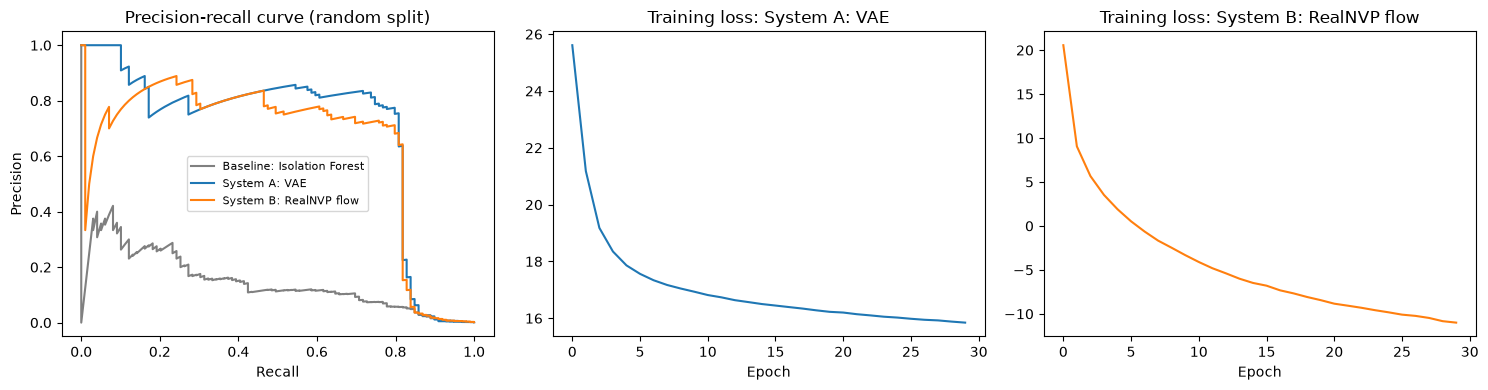

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for model_name, colour in zip(MODELS, COLOURS):
    result = trained[("random", model_name)]
    precision, recall, _ = precision_recall_curve(splits["random"]["y_test"], result["test_scores"])
    axes[0].plot(recall, precision, color=colour, label=MODEL_LABELS[model_name])
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curve (random split)")
axes[0].legend(fontsize=8)

for ax, model_name in zip(axes[1:], ["vae", "flow"]):
    ax.plot(trained[("random", model_name)]["losses"], color=COLOURS[MODELS.index(model_name)])
    ax.set_xlabel("Epoch")
    ax.set_title(f"Training loss: {MODEL_LABELS[model_name]}")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "pr_curves_and_training.png", dpi=150, bbox_inches="tight")
plt.show()

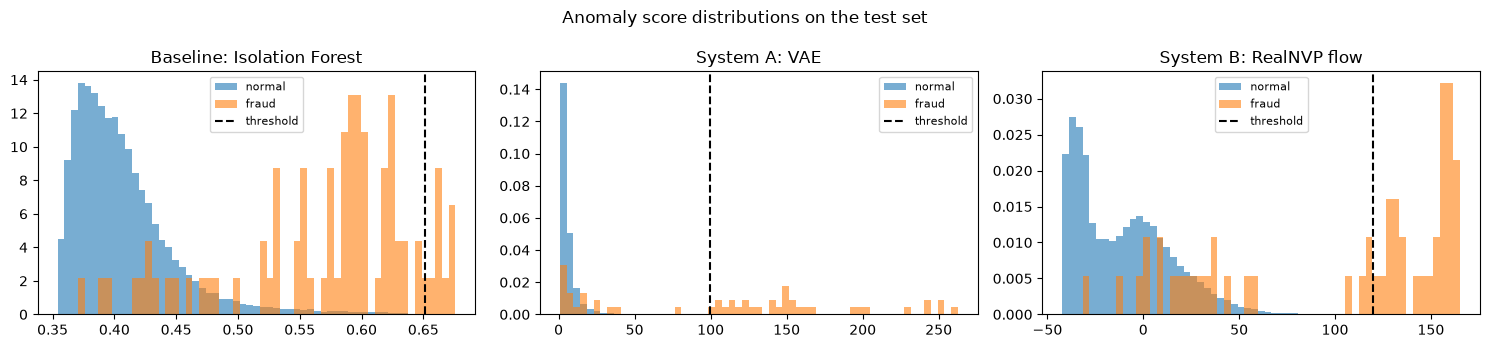

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, model_name in zip(axes, MODELS):
    scores = trained[("random", model_name)]["test_scores"]
    labels = splits["random"]["y_test"]
    bins = np.linspace(np.percentile(scores, 0.5), np.percentile(scores, 99.9), 60)
    ax.hist(scores[labels == 0], bins=bins, alpha=0.6, density=True, label="normal")
    ax.hist(scores[labels == 1], bins=bins, alpha=0.6, density=True, label="fraud")
    ax.axvline(trained[("random", model_name)]["threshold"], color="k", linestyle="--", label="threshold")
    ax.set_title(MODEL_LABELS[model_name])
    ax.legend(fontsize=8)
fig.suptitle("Anomaly score distributions on the test set")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "score_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Stress Tests

| Stress test | What changes | Business meaning |
|---|---|---|
| `drift` | Train on earlier payments, test on later ones (time split) | Fraud and customer behaviour change over time |
| `noise_0.1`, `noise_0.3`, `noise_0.5` | Gaussian noise with that standard deviation added to the standardised test features | Noisy data from a new payment provider or device |
| threshold curve | Business cost at every flag rate | How sensitive the decision is to the chosen threshold |

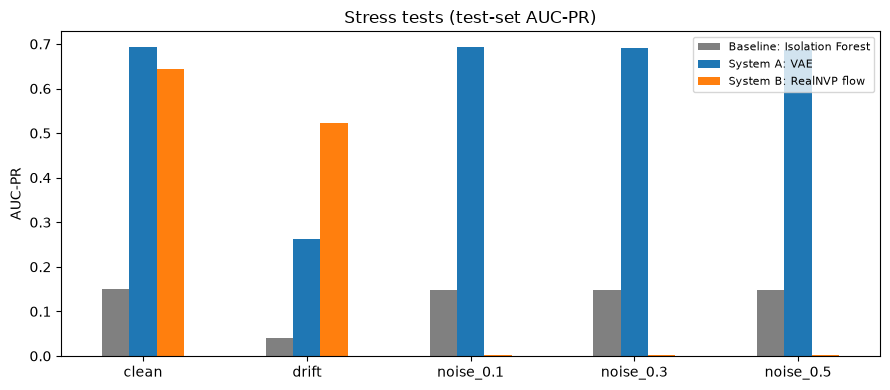

condition,clean,drift,noise_0.1,noise_0.3,noise_0.5
model,,,,,
Baseline: Isolation Forest,0.151,0.040,0.149,0.147,0.147
System A: VAE,0.694,0.262,0.693,0.690,0.686
System B: RealNVP flow,0.644,0.523,0.002,0.001,0.001


In [13]:
random_split = splits["random"]
noise = np.random.default_rng(SPLIT_SEED).standard_normal(random_split["x_test"].shape)

stress_rows = []
for model_name in MODELS:
    clean = trained[("random", model_name)]
    drift = trained[("time", model_name)]
    conditions = {
        "clean": (random_split["y_test"], clean["test_scores"], clean["threshold"]),
        "drift": (splits["time"]["y_test"], drift["test_scores"], drift["threshold"]),
    }
    for level in NOISE_LEVELS:
        noisy_test = (random_split["x_test"] + level * noise).astype(np.float32)
        conditions[f"noise_{level}"] = (random_split["y_test"], anomaly_scores(model_name, clean["model"], noisy_test), clean["threshold"])
    for condition, (true_labels, scores, threshold) in conditions.items():
        stress_rows.append({"model": model_name, "condition": condition, **evaluate(true_labels, scores, threshold)})

stress_results = pd.DataFrame(stress_rows)
stress_auc_pr = stress_results.pivot(index="model", columns="condition", values="auc_pr").reindex(MODELS)
stress_auc_pr = stress_auc_pr[["clean", "drift"] + [f"noise_{level}" for level in NOISE_LEVELS]]

ax = stress_auc_pr.rename(index=MODEL_LABELS).T.plot(kind="bar", figsize=(9, 4), color=COLOURS)
ax.set_ylabel("AUC-PR")
ax.set_xlabel("")
ax.set_title("Stress tests (test-set AUC-PR)")
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "stress_tests.png", dpi=150, bbox_inches="tight")
plt.show()

stress_auc_pr.rename(index=MODEL_LABELS).round(3)

### 5.1 Can training noise fix the flow's collapse?

The flow fails under small input noise because it learns a very sharp density for normal payments: a 0.1 SD step off the region where normal payments sit costs a normal payment more likelihood than a real fraud has, so the ranking flips (AUC-ROC below 0.5). A standard remedy is to add small Gaussian noise to every training batch, which smooths the learned density.

This cell trains one more flow on each split with `TRAINING_NOISE` added during training (seed 0, everything else unchanged) and compares it with the flow trained without noise and with the VAE. The threshold is not needed here because the table reports AUC-PR, which does not depend on it.

In [14]:
def train_flow_with_noise(x_train, seed, noise_sd):
    """Train the flow like train_deep_model, adding Gaussian noise to every training batch."""
    set_seed(seed)
    model = RealNVP(x_train.shape[1], HIDDEN_SIZE, FLOW_LAYERS).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    data = torch.tensor(x_train, device=DEVICE)
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(len(data), device=DEVICE)
        for i in range(0, len(data), BATCH_SIZE):
            batch = data[order[i:i + BATCH_SIZE]]
            batch = batch + noise_sd * torch.randn_like(batch)
            loss = model.loss(batch)
            optimiser.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimiser.step()
    return model.eval(), time.perf_counter() - start


def flow_results(label, random_model, time_model, train_seconds):
    """AUC-PR of a flow on clean, later (drift) and noisy test payments, plus clean recall at 1% FPR."""
    clean_scores = anomaly_scores("flow", random_model, random_split["x_test"])
    row = {
        "flow": label,
        "train_seconds": train_seconds,
        "clean": average_precision_score(random_split["y_test"], clean_scores),
        "clean_recall_at_1pct_fpr": recall_at_fpr(random_split["y_test"], clean_scores, TARGET_FALSE_POSITIVE_RATE),
        "drift": average_precision_score(splits["time"]["y_test"], anomaly_scores("flow", time_model, splits["time"]["x_test"])),
    }
    for level in NOISE_LEVELS:
        noisy_test = (random_split["x_test"] + level * noise).astype(np.float32)
        row[f"noise_{level}"] = average_precision_score(random_split["y_test"], anomaly_scores("flow", random_model, noisy_test))
    return row


first_flow_run = runs[(runs["split"] == "random") & (runs["model"] == "flow") & (runs["seed"] == TRAINING_SEEDS[0])]
noisy_random_flow, noisy_seconds = train_flow_with_noise(random_split["x_train"], TRAINING_SEEDS[0], TRAINING_NOISE)
noisy_time_flow, _ = train_flow_with_noise(splits["time"]["x_train"], TRAINING_SEEDS[0], TRAINING_NOISE)

noise_fix = pd.DataFrame([
    flow_results("flow, trained without noise", trained[("random", "flow")]["model"], trained[("time", "flow")]["model"], first_flow_run["train_seconds"].iloc[0]),
    flow_results(f"flow, trained with noise SD {TRAINING_NOISE}", noisy_random_flow, noisy_time_flow, noisy_seconds),
]).set_index("flow")
noise_fix.loc["VAE, for comparison", stress_auc_pr.columns] = stress_auc_pr.loc["vae"]
noise_fix = noise_fix.round(3)
noise_fix

,train_seconds,clean,clean_recall_at_1pct_fpr,drift,noise_0.1,noise_0.3,noise_0.5
flow,,,,,,,
"flow, trained without noise",97.944,0.644,0.828,0.523,0.002,0.001,0.001
"flow, trained with noise SD 0.1",99.684,0.696,0.848,0.516,0.659,0.034,0.006
"VAE, for comparison",NaN,0.694,NaN,0.262,0.693,0.690,0.686


## 6. Fairness and Explainability

### 6.1 Performance by payment size

A model that only catches large frauds leaves small-value fraud (often card testing) unchecked, and a model that wrongly declines many small payments annoys everyday customers. Test payments are split into amount bands.

In [15]:
AMOUNT_BANDS = [0, 10, 100, np.inf]
BAND_NAMES = ["small (< 10 EUR)", "medium (10-100 EUR)", "large (> 100 EUR)"]

bands = pd.cut(random_split["amount_test"], AMOUNT_BANDS, labels=BAND_NAMES, right=False)
fairness_rows = []
for model_name in MODELS:
    result = trained[("random", model_name)]
    flagged = result["test_scores"] >= result["threshold"]
    for band in BAND_NAMES:
        in_band = np.asarray(bands == band)
        true_labels = random_split["y_test"][in_band]
        fairness_rows.append({
            "model": model_name,
            "amount_band": band,
            "payments": int(in_band.sum()),
            "frauds": int(true_labels.sum()),
            "recall": flagged[in_band][true_labels == 1].mean(),
            "false_positive_rate": flagged[in_band][true_labels == 0].mean(),
        })

fairness = pd.DataFrame(fairness_rows).round(4)
fairness.pivot(index="model", columns="amount_band", values=["recall", "false_positive_rate"]).reindex(MODELS)

recall                                       \
amount_band      large (> 100 EUR) medium (10-100 EUR) small (< 10 EUR)   
model                                                                     
isolation_forest            0.3214                0.20           0.2391   
vae                         0.8214                0.88           0.7609   
flow                        0.7857                0.88           0.7174   

                 false_positive_rate                                       
amount_band        large (> 100 EUR) medium (10-100 EUR) small (< 10 EUR)  
model                                                                      
isolation_forest              0.0048              0.0003           0.0008  
vae                           0.0011              0.0003           0.0002  
flow                          0.0010              0.0005           0.0004

### 6.2 Which features drive the score?

A fraud analyst needs to know *why* a payment was flagged.
* **VAE:** the reconstruction error can be split per feature, so the features the VAE could not rebuild are the explanation.
* **Flow:** the likelihood is not split per feature, so the gradient of `-log p(x)` with respect to each feature is used (how much the score changes when that feature changes).

The charts show the average for the frauds in the test set.

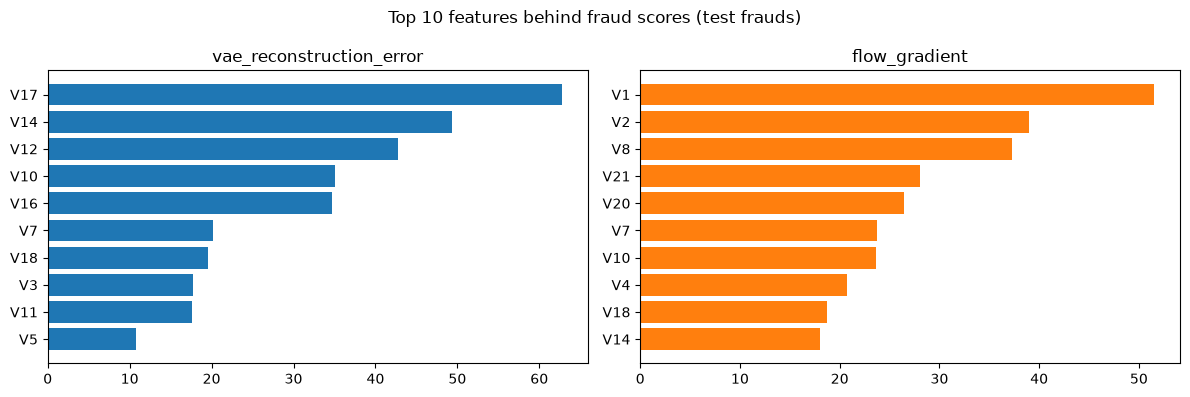

Features in both top-10 lists: ['V10', 'V14', 'V18', 'V7']


In [16]:
test_frauds = torch.tensor(random_split["x_test"][random_split["y_test"] == 1], device=DEVICE)

vae_model = trained[("random", "vae")]["model"]
vae_importance = vae_model.feature_errors(test_frauds).mean(dim=0).cpu().numpy()

flow_model = trained[("random", "flow")]["model"]
frauds_with_grad = test_frauds.clone().requires_grad_(True)
(-flow_model.log_likelihood(frauds_with_grad)).sum().backward()
flow_importance = frauds_with_grad.grad.abs().mean(dim=0).cpu().numpy()

importance = pd.DataFrame({"vae_reconstruction_error": vae_importance, "flow_gradient": flow_importance}, index=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, colour in zip(axes, importance.columns, ["tab:blue", "tab:orange"]):
    top = importance[column].sort_values(ascending=False).head(10)
    ax.barh(top.index[::-1], top.values[::-1], color=colour)
    ax.set_title(column)
fig.suptitle("Top 10 features behind fraud scores (test frauds)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

overlap = set(importance["vae_reconstruction_error"].nlargest(10).index) & set(importance["flow_gradient"].nlargest(10).index)
print(f"Features in both top-10 lists: {sorted(overlap)}")

## 7. Business and Environmental Cost

| Assumption | Value | Meaning |
|---|---|---|
| `EUR_TO_AUD` | 1.65 | The dataset amounts are in euros. Check the rate on the day |
| `CHARGEBACK_FEE_AUD` | 25 | Fee charged by the bank for each fraud that gets through |
| `FALSE_DECLINE_AUD` | 15 | Lost margin and customer frustration when a genuine payment is blocked |
| `REVIEW_AUD` | 3 | Analyst time to check one flagged payment |
| `PAYMENTS_PER_MONTH` | 600,000 | About 20,000 orders per day |

A missed fraud costs its amount plus the chargeback fee. The threshold with the lowest cost on the **validation** set is used for each model. "No model" means every payment is approved.

In [17]:
EUR_TO_AUD = 1.65
CHARGEBACK_FEE_AUD = 25
FALSE_DECLINE_AUD = 15
REVIEW_AUD = 3
PAYMENTS_PER_MONTH = 600_000
POWER_KW = {"cuda": 0.115, "cpu": 0.065}
ELECTRICITY_AUD_PER_KWH = 0.30


def business_cost(true_labels, amounts, flagged):
    """Cost of missed frauds, wrongly declined payments and analyst reviews, in AUD."""
    missed = (true_labels == 1) & ~flagged
    wrongly_declined = (true_labels == 0) & flagged
    missed_cost = (amounts[missed] * EUR_TO_AUD + CHARGEBACK_FEE_AUD).sum()
    return missed_cost + wrongly_declined.sum() * FALSE_DECLINE_AUD + flagged.sum() * REVIEW_AUD


def cheapest_threshold(true_labels, amounts, scores):
    """Threshold with the lowest business cost (chosen on the validation set)."""
    candidates = np.quantile(scores, np.linspace(0.9, 0.9999, 300))
    costs = [business_cost(true_labels, amounts, scores >= t) for t in candidates]
    return candidates[int(np.argmin(costs))]


y_test, amount_test = random_split["y_test"], random_split["amount_test"]
scale = PAYMENTS_PER_MONTH / len(y_test)
no_model_cost = business_cost(y_test, amount_test, np.zeros(len(y_test), dtype=bool))
cost_rows = [{"model": "no_model", "aud_per_month": no_model_cost * scale}]

for model_name in MODELS:
    result = trained[("random", model_name)]
    threshold = cheapest_threshold(random_split["y_val"], random_split["amount_val"], result["val_scores"])
    flagged = result["test_scores"] >= threshold
    train_seconds = random_runs[random_runs["model"] == model_name]["train_seconds"].mean()
    device = "cpu" if model_name == "isolation_forest" else DEVICE
    cost_rows.append({
        "model": model_name,
        "flag_rate": flagged.mean(),
        "fraud_caught_aud": amount_test[flagged & (y_test == 1)].sum() * EUR_TO_AUD * scale,
        "aud_per_month": business_cost(y_test, amount_test, flagged) * scale,
        "training_wh": train_seconds / 3600 * POWER_KW[device] * 1000,
    })

cost_table = pd.DataFrame(cost_rows).set_index("model")
cost_table["saving_vs_no_model_aud"] = cost_table.loc["no_model", "aud_per_month"] - cost_table["aud_per_month"]
cost_table.round(3)

,aud_per_month,flag_rate,fraud_caught_aud,training_wh,saving_vs_no_model_aud
model,,,,,
no_model,197686.291,NaN,NaN,NaN,0.000
isolation_forest,136503.434,0.002,75971.664,0.009,61182.857
vae,56622.132,0.002,127644.686,1.155,141064.159
flow,63296.024,0.002,123435.596,3.142,134390.267


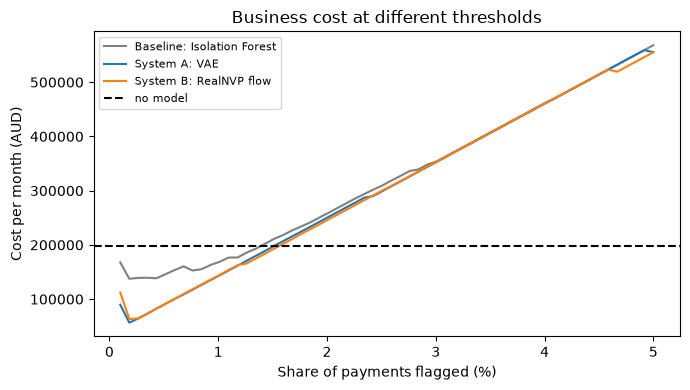

In [18]:
flag_rates = np.linspace(0.001, 0.05, 60)
fig, ax = plt.subplots(figsize=(7, 4))
for model_name, colour in zip(MODELS, COLOURS):
    scores = trained[("random", model_name)]["test_scores"]
    costs = [business_cost(y_test, amount_test, scores >= np.quantile(scores, 1 - rate)) * scale for rate in flag_rates]
    ax.plot(flag_rates * 100, costs, color=colour, label=MODEL_LABELS[model_name])
ax.axhline(no_model_cost * scale, color="k", linestyle="--", label="no model")
ax.set_xlabel("Share of payments flagged (%)")
ax.set_ylabel("Cost per month (AUD)")
ax.set_title("Business cost at different thresholds")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "threshold_cost_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Self-Evaluation (User Feedback)

The users of this system are fraud analysts, so the self-evaluation is from an analyst's point of view after looking at the results above. The cell creates `self_evaluation.csv` once (it is never overwritten). Score each model 1-5:

| Column | Question |
|---|---|
| `catches_costly_fraud` | Does it catch the frauds that cost the most? |
| `explainable` | Can I tell a customer or the bank why a payment was blocked? |
| `robust_to_drift` | Does it still work on later payments? |
| `fair` | Are small everyday payments treated reasonably? |
| `easy_to_run` | Training time, tuning effort, stability |

In [19]:
FEEDBACK_COLUMNS = ["catches_costly_fraud", "explainable", "robust_to_drift", "fair", "easy_to_run"]

if not SELF_EVALUATION_PATH.exists():
    template = pd.DataFrame({"model": MODELS})
    for column in FEEDBACK_COLUMNS + ["notes"]:
        template[column] = ""
    save_table(template, SELF_EVALUATION_PATH)
    print(f"Template created: {SELF_EVALUATION_PATH}")

self_evaluation = pd.read_csv(SELF_EVALUATION_PATH).set_index("model")
if self_evaluation[FEEDBACK_COLUMNS].isna().all().all():
    print("No scores yet. Fill in self_evaluation.csv and run this cell again.")
else:
    self_evaluation["average"] = self_evaluation[FEEDBACK_COLUMNS].mean(axis=1).round(2)
    display(self_evaluation.rename(index=MODEL_LABELS))

,catches_costly_fraud,explainable,robust_to_drift,fair,easy_to_run,notes,average
model,,,,,,,
Baseline: Isolation Forest,2,2,1,2,5,"AUC-PR 0.158, recall 0.64 at 1% FPR, catches a...",2.4
System A: VAE,5,4,3,4,4,"AUC-PR 0.690, recall 0.83 at 1% FPR, catches a...",4.0
System B: RealNVP flow,4,2,2,4,2,"AUC-PR 0.624, recall 0.84 at 1% FPR, catches a...",2.8


## 9. Saving Results

In [20]:
save_table(split_table, RESULTS_DIR / "splits.csv")
save_table(summary.reset_index(), RESULTS_DIR / "technical_summary.csv")
save_table(mean_table.reset_index(), RESULTS_DIR / "technical_means.csv")
save_table(stress_results, RESULTS_DIR / "stress_results.csv")
save_table(noise_fix.reset_index(), RESULTS_DIR / "noise_training_fix.csv")
save_table(fairness, RESULTS_DIR / "fairness_by_amount.csv")
save_table(importance.reset_index(names="feature"), RESULTS_DIR / "feature_importance.csv")
save_table(cost_table.reset_index(), RESULTS_DIR / "business_cost.csv")

for path in sorted(RESULTS_DIR.iterdir()):
    print(path.name)

business_cost.csv
environment.json
fairness_by_amount.csv
feature_importance.csv
feature_importance.png
noise_training_fix.csv
pr_curves_and_training.png
score_distributions.png
splits.csv
stress_results.csv
stress_tests.png
technical_means.csv
technical_summary.csv
threshold_cost_curve.png
training_runs.csv
